# Extension H: A Shortest-Path Transport Network

In [1]:
import numpy as np
from scipy.optimize import root
import pandas as pd
import networkx as nx
from geopy import distance
import math
from itertools import combinations

## Regions

In [2]:
regions = pd.DataFrame({"code": ["SE33", "SE32", "SE31", "SE12", "SE11", "SE23", "SE21", "SE22"],
                        "region": ["Övre Norrland", 
                                   "Mellersta Norrland", 
                                   "Norra Mellansverige", 
                                   "Östra Mellansverige", 
                                   "Stockholm",
                                   "Västsverige",
                                   "Småland med öarna",
                                   "Sydsverige"],
                        "lat": [65.2, 62.8, 60.7, 59.2, 59.33, 57.9, 57.3, 56.1],
                        "lon": [20, 16.8, 14.6, 16, 18.07, 12.5, 15.2, 13.4]})

## Physical transport network

Distances

In [3]:
edge_nodes = [[0, 1], 
              [1, 2], 
              [2, 3], 
              [2, 5], 
              [3, 4], 
              [3, 5],
              [3, 6],
              [5, 6],
              [5, 7],
              [6, 7]]

edges = []

for i, j in edge_nodes:
    node_from = regions.code[i]
    node_to = regions.code[j]

    dist = distance.distance(
        (regions.lat[i], regions.lon[i]), 
            (regions.lat[j], regions.lon[j]))

    edges.append((node_from, node_to, dist.km))

## Iceberg transport costs

In [4]:
kappa = 0.00030

for i in range(len(edges)):
    tau_e = math.exp(kappa * edges[i][2]) - 1
    edges[i] += (tau_e, )

In [5]:
edges_costs = []

for e in edges:
    node_from = e[0]
    node_to = e[1]
    iceberg_cost = e[3]

    additive_cost = math.log(1 + iceberg_cost)

    edges_costs.append((node_from, node_to, additive_cost))

In [6]:
G = nx.Graph()

G.add_weighted_edges_from(edges_costs)

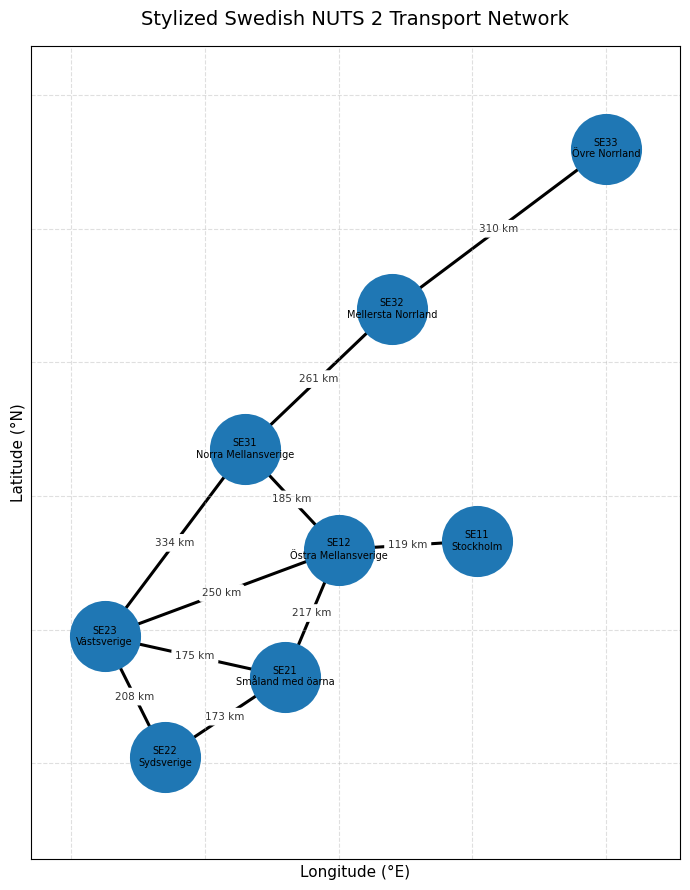

In [12]:
import matplotlib.pyplot as plt

# 1. Create a position dictionary mapping node codes to (lon, lat) -> (x, y)
pos = {
    row['code']: (row['lon'], row['lat']) 
    for _, row in regions.iterrows()
}

# 2. Extract edge labels (distances in km) from your edges list
edge_labels = {
    (e[0], e[1]): f"{e[2]:.0f} km" 
    for e in edges
}

# 3. Create node labels showing both region code and name
node_labels = {
    row['code']: f"{row['code']}\n{row['region']}" 
    for _, row in regions.iterrows()
}

# 4. Plot the network
plt.figure(figsize=(7, 9))

# Draw edges and nodes
nx.draw_networkx_edges(G, pos, width=2.2, edge_color="black")
nx.draw_networkx_nodes(G, pos, node_size=2500, node_color="#1f77b4",  linewidths=1.2)

# Draw node labels (inside / adjacent to nodes)
nx.draw_networkx_labels(G, pos, labels=node_labels, font_size=7, font_color="black")

# Draw distance labels along the edges
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7.5, font_color="#333333", rotate=False)

# Add geographical axes and styling
plt.title("Stylized Swedish NUTS 2 Transport Network", fontsize=14, pad=15)
plt.xlabel("Longitude (°E)", fontsize=11)
plt.ylabel("Latitude (°N)", fontsize=11)

# Ensure equal aspect ratio so Sweden doesn't look stretched or compressed
plt.gca().set_aspect('equal', adjustable='datalim')

# Add margins around the outermost nodes so labels aren't clipped
plt.margins(0.12)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
#plt.show()

plt.savefig("fig/transport_network.pdf")

In [49]:
ordered_pairs = list(combinations(regions.code, 2))

In [50]:
region_codes = regions['code'].tolist()
T = pd.DataFrame(0.0, index=region_codes, columns=region_codes)
pair_paths = []

for i, j in ordered_pairs:
    additive_cost = nx.dijkstra_path_length(G, i, j)
    path = nx.dijkstra_path(G, i, j)

    t_ij = math.exp(additive_cost) - 1
    
    T.loc[i, j] = t_ij
    T.loc[j, i] = t_ij
    pair_paths.append([i, j, path])

T.round(4).to_excel("tables/benchmark_shortest_path_tc_matrix.xlsx")

Examples of shortest routes involving intermediate nodes => f.ex. SE33 -> SE11

In [51]:
pair_paths

[['SE33', 'SE32', ['SE33', 'SE32']],
 ['SE33', 'SE31', ['SE33', 'SE32', 'SE31']],
 ['SE33', 'SE12', ['SE33', 'SE32', 'SE31', 'SE12']],
 ['SE33', 'SE11', ['SE33', 'SE32', 'SE31', 'SE12', 'SE11']],
 ['SE33', 'SE23', ['SE33', 'SE32', 'SE31', 'SE23']],
 ['SE33', 'SE21', ['SE33', 'SE32', 'SE31', 'SE12', 'SE21']],
 ['SE33', 'SE22', ['SE33', 'SE32', 'SE31', 'SE23', 'SE22']],
 ['SE32', 'SE31', ['SE32', 'SE31']],
 ['SE32', 'SE12', ['SE32', 'SE31', 'SE12']],
 ['SE32', 'SE11', ['SE32', 'SE31', 'SE12', 'SE11']],
 ['SE32', 'SE23', ['SE32', 'SE31', 'SE23']],
 ['SE32', 'SE21', ['SE32', 'SE31', 'SE12', 'SE21']],
 ['SE32', 'SE22', ['SE32', 'SE31', 'SE23', 'SE22']],
 ['SE31', 'SE12', ['SE31', 'SE12']],
 ['SE31', 'SE11', ['SE31', 'SE12', 'SE11']],
 ['SE31', 'SE23', ['SE31', 'SE23']],
 ['SE31', 'SE21', ['SE31', 'SE12', 'SE21']],
 ['SE31', 'SE22', ['SE31', 'SE23', 'SE22']],
 ['SE12', 'SE11', ['SE12', 'SE11']],
 ['SE12', 'SE23', ['SE12', 'SE23']],
 ['SE12', 'SE21', ['SE12', 'SE21']],
 ['SE12', 'SE22', ['SE1

## Functions

### Production

In [52]:
def output(phi, L_d, delta_l, delta_x, X_d):
    return phi * ((L_d / delta_l) ** delta_l) * ((X_d / delta_x) ** delta_x)

def output_value(M, b):
    return np.linalg.solve(np.eye(M.shape[0]) - M, b)

def unit_costs(phi, w, delta_l, delta_x, intermediate_price_index):
    return (1 / phi) * (w ** delta_l) * (intermediate_price_index ** delta_x)

def labour_demands(delta_l, output_value, w):
    return delta_l * output_value / w

### Prices

In [53]:
def price_factory_gate(w, A):
    return w / A

def price_ij(t, p):
    return p[:, np.newaxis] * (1 + t)

### Households

In [54]:
def income(w, L_bar):
    return w * L_bar

def armington_shares(p_ij, beta, eta_H):
    return (beta * p_ij ** (1 - eta_H)) / np.sum(beta * p_ij ** (1 - eta_H), axis=0)

def household_price_index(p_ij, beta, eta_H):
    return (np.sum(beta * p_ij ** (1 - eta_H), axis=0)) ** (1 / (1 - eta_H))

def household_bilateral_demand(s_H, I, p_ij):
    return s_H * I / p_ij

def household_real_consumption(I, P_H):
    return I / P_H

### Intermediate goods

In [55]:
def intermediate_shares(p_ij, gamma, eta_X):
    return (gamma * p_ij ** (1 - eta_X)) / np.sum(gamma * p_ij ** (1 - eta_X), axis=0)

def intermediate_price_index(p_ij, gamma, eta_X):
    return (np.sum(gamma * p_ij ** (1 - eta_X), axis=0)) ** (1 / (1 - eta_X))

def quantity_arriving_at_firm(s_X, delta_x, V, p_ij):
    return s_X * delta_x * V / p_ij

def intermediate_composite(gamma, eta_X, X_ij):
    return np.sum((gamma ** (1/eta_X)) * (X_ij ** ((eta_X - 1)/eta_X)), axis=0) ** (eta_X/(eta_X - 1))

### Final demands

In [56]:
def final_demand(armington_shares, income):
    return np.sum(armington_shares * income, axis=1)

def input_output(intermediate_shares, delta_x):
    return intermediate_shares * delta_x

### Market clearing / residuals

In [57]:
def goods_market_clearing(Y, t, Z, X_d):
    return Y - np.sum((1 + t) * (Z + X_d), axis=1)

def value_market_clearing(p, w, t, beta, gamma, eta_H, eta_X, phi, delta_l, delta_x, L_bar):
    p_ij = price_ij(t, p)
    P_H = household_price_index(p_ij, beta, eta_H)
    s_H = armington_shares(p_ij, beta, eta_H)
    P_X = intermediate_price_index(p_ij, gamma, eta_X)
    s_X = intermediate_shares(p_ij, gamma, eta_X)
    I = income(w, L_bar)

    b = final_demand(s_H, I)
    M = input_output(s_X, delta_x)

    V = output_value(M, b)

    # Calculate unit costs and labour demands
    c = unit_costs(phi, w, delta_l, delta_x, P_X)
    L_d = labour_demands(delta_l, V, w)

    R_p = p - c                
    R_L = L_d[1:] - L_bar[1:]  

    return np.concatenate([R_p, R_L])

## Modelling parameters

In [58]:
L_bar = np.array([100] * 8)
phi = np.array([1] * 8)
delta_l = np.array([0.60] * 8)
delta_x = np.array([0.40] * 8)
eta_H = 4
eta_X = 4
beta = np.full((8, 8), 0.45 / 7); np.fill_diagonal(beta, 0.55)
gamma = np.full((8, 8), 0.45 / 7); np.fill_diagonal(gamma, 0.55)
t = T
theta = 0.5

## Benchmark

In [59]:
def residuals(x):
    w = np.concatenate(([1.0], np.exp(x[8:])))
    p = np.exp(x[:8])

    value_clearing = value_market_clearing(p, w, t, beta, gamma, eta_H, eta_X, phi, delta_l, delta_x, L_bar)

    return value_clearing

In [60]:
res = root(residuals, np.zeros(15))

p_sol = np.exp(res.x[:8])
w_sol = np.concatenate(([1.0], np.exp(res.x[8:])))

print("Solution found:", res.success)
print("Solution for w:", w_sol)

Solution found: True
Solution for w: [1.         1.02701823 1.04506883 1.05090586 1.03755794 1.0425092
 1.04152196 1.02799291]


In [61]:
p_ij_sol = price_ij(t, p_sol)
P_H_sol = household_price_index(p_ij_sol, beta, eta_H)
s_H_sol = armington_shares(p_ij_sol, beta, eta_H)
P_X_sol = intermediate_price_index(p_ij_sol, gamma, eta_X)
s_X_sol = intermediate_shares(p_ij_sol, gamma, eta_X)
I_sol = income(w_sol, L_bar)

b_sol = final_demand(s_H_sol, I_sol)
M_sol = input_output(s_X_sol, delta_x)

V_sol = output_value(M_sol, b_sol)

L_d_sol = labour_demands(delta_l, V_sol, w_sol)

Q_sol = household_real_consumption(I_sol, P_H_sol)

print("Prices:", p_sol)
print("Wages:", w_sol)
print("Household Price Index:", P_H_sol)
print("Intermediate Price Index:", P_X_sol)
print("Labour Demands:", L_d_sol)
print("Output Values:", V_sol)
print("Real consumption:", Q_sol)
print("Household expenditure shares:", s_H_sol)

Prices: [1.06000607 1.06946786 1.07569707 1.07769605 1.07311386 1.07481813
 1.07447875 1.06980607]
Wages: [1.         1.02701823 1.04506883 1.05090586 1.03755794 1.0425092
 1.04152196 1.02799291]
Household Price Index: SE33    1.156834
SE32    1.136455
SE31    1.123331
SE12    1.119167
SE11    1.128745
SE23    1.125169
SE21    1.125880
SE22    1.135736
dtype: float64
Intermediate Price Index: SE33    1.156834
SE32    1.136455
SE31    1.123331
SE12    1.119167
SE11    1.128745
SE23    1.125169
SE21    1.125880
SE22    1.135736
dtype: float64
Labour Demands: [100. 100. 100. 100. 100. 100. 100. 100.]
Output Values: [166.66666667 171.16970533 174.17813837 175.15097605 172.92632357
 173.75153381 173.58699293 171.33215213]
Real consumption: SE33    86.442858
SE32    90.370366
SE31    93.033054
SE12    93.900695
SE11    91.921348
SE23    92.653596
SE21    92.507406
SE22    90.513353
dtype: float64
Household expenditure shares:           SE33      SE32      SE31      SE12      SE11      SE23  

### Verification of zero profit (price residuals = 0), labour-market clearing (differences between L_d and L_bar = 0) ...

In [62]:
# "Evaluate the residual vector R(x*) at the reported solution and verify that L_1^d - \bar{L}_1 ≈ 0."
print("Price and labour residuals at solution:", residuals(res.x), "– Within 2e-11, so close to zero")

print("Difference between L_1^d and L_bar_1:", L_d_sol[0] - L_bar[0], "– Within 1.1e-10, so close to zero")

Price and labour residuals at solution: [-4.90940621e-13 -2.64011035e-13  5.44009282e-13  1.78101978e-12
 -1.79856130e-13  2.00728323e-13  9.79216708e-14 -2.76889622e-13
 -1.92983407e-11 -1.60014224e-11 -1.39976919e-11 -1.30739863e-11
 -1.23918653e-11 -1.19371180e-11 -1.81188398e-11] – Within 2e-11, so close to zero
Difference between L_1^d and L_bar_1: 1.0895462310145376e-10 – Within 1.1e-10, so close to zero


### ... and physical goods-market clearing (verification of equations (75))

In [63]:
X_ij_sol = quantity_arriving_at_firm(s_X_sol, delta_x, V_sol, p_ij_sol)
X_j_sol = intermediate_composite(gamma, eta_X, X_ij_sol)
Y_sol = output(phi, L_d_sol, delta_l, delta_x, X_j_sol)

Z_sol = household_bilateral_demand(s_H_sol, I_sol, p_ij_sol)

residual_goods_market = goods_market_clearing(Y_sol, t, Z_sol, X_ij_sol)

print("Total output:", Y_sol)
print("Goods Market clearing:", residual_goods_market, "– Within 2.7e-10, so close to zero")

Total output: SE33    157.231804
SE32    160.051285
SE31    161.921180
SE12    162.523539
SE11    161.144432
SE23    161.656682
SE21    161.554608
SE22    160.152533
dtype: float64
Goods Market clearing: SE33   -7.281642e-11
SE32   -3.950618e-11
SE31    8.188294e-11
SE12    2.685567e-10
SE11   -2.702905e-11
SE23    3.021228e-11
SE21    1.475087e-11
SE22   -4.149570e-11
dtype: float64 – Within 2.7e-10, so close to zero


## Input-output identities

In [64]:
io_residual = V_sol - (b_sol + M_sol @ V_sol)
value_output_residual = V_sol - (p_sol * Y_sol)
print("Max abs IO identity residual V - (b + MV):", np.max(np.abs(io_residual)))
print("Max abs value identity residual V - p*Y:", np.max(np.abs(value_output_residual)))

Max abs IO identity residual V - (b + MV): 2.842170943040401e-14
Max abs value identity residual V - p*Y: 2.894466888392344e-10


Residuals close to zero $\Rightarrow$ identities hold

## Improvement of one physical transport link

We choose edge 1 (SE33 -> SE32).

In [65]:
edges_costs_new = edges_costs.copy()

tau_0 = edges[0][3]
tau_1 = (1 - theta) * tau_0

edges_costs_new[0] = ('SE33', 'SE32', math.log(1 + tau_1))

In [66]:
G_new = nx.Graph()

G_new.add_weighted_edges_from(edges_costs_new)

In [67]:
T_1 = pd.DataFrame(0.0, index=region_codes, columns=region_codes)
pair_paths_new = []

for i, j in ordered_pairs:
    additive_cost = nx.dijkstra_path_length(G_new, i, j)
    path = nx.dijkstra_path(G_new, i, j)

    t_ij = math.exp(additive_cost) - 1
    
    T_1.loc[i, j] = t_ij
    T_1.loc[j, i] = t_ij
    pair_paths_new.append([i, j, path])

## Identification of network effects

Which origin-destination pairs obtain a lower $t_{ij}$?

In [68]:
T - T_1

,SE33,SE32,SE31,SE12,SE11,SE23,SE21,SE22
SE33,0.000000,0.048716,0.052688,0.055687,0.05771,0.058242,0.059428,0.061987
SE32,0.048716,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
SE31,0.052688,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
SE12,0.055687,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
SE11,0.057710,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
SE23,0.058242,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
SE21,0.059428,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
SE22,0.061987,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000


Which shortest routes remain unchanged? / Which shortest routes change?

In [69]:
def which_routes_change(pair_paths, pair_paths_new):
    for p1, p2 in zip(pair_paths, pair_paths_new):
        if p1 == p2:
            print(f"Shortest path between {p1[:2]} did not change.")
        else:
            print(f"Shortest path between {p1[:2]} changed. Old path: {p1[2]}; New path: {p2[2]}.")

which_routes_change(pair_paths, pair_paths_new)

Shortest path between ['SE33', 'SE32'] did not change.
Shortest path between ['SE33', 'SE31'] did not change.
Shortest path between ['SE33', 'SE12'] did not change.
Shortest path between ['SE33', 'SE11'] did not change.
Shortest path between ['SE33', 'SE23'] did not change.
Shortest path between ['SE33', 'SE21'] did not change.
Shortest path between ['SE33', 'SE22'] did not change.
Shortest path between ['SE32', 'SE31'] did not change.
Shortest path between ['SE32', 'SE12'] did not change.
Shortest path between ['SE32', 'SE11'] did not change.
Shortest path between ['SE32', 'SE23'] did not change.
Shortest path between ['SE32', 'SE21'] did not change.
Shortest path between ['SE32', 'SE22'] did not change.
Shortest path between ['SE31', 'SE12'] did not change.
Shortest path between ['SE31', 'SE11'] did not change.
Shortest path between ['SE31', 'SE23'] did not change.
Shortest path between ['SE31', 'SE21'] did not change.
Shortest path between ['SE31', 'SE22'] did not change.
Shortest p

$\Rightarrow$ All shortest routes remain unchanged. This is because the improvement happened on the only edge that connects Övre Norrland and Mellersta Norrland (traffic _needs_ to use this edge).

How many benchmark shortest paths use the improved edge?    

In [70]:
def usage_improved_edge(e, pair_paths):
    count = 0
    for pair_path in pair_paths:
        path = pair_path[2]
        combs = zip(path[:-1], path[1:])
        
        for comb in combs:
            if set(comb) == set(e):
                count += 1
                break
                
    return count

usage_improved_edge(['SE33', 'SE32'], pair_paths)

7

$\Rightarrow$ Seven benchmark shortest paths use the improved edge.

How large is the reduction in effective bilateral transport costs?

In [71]:
# We need to set all 0-transport costs to 1 for relative comparison
T_adj = T.to_numpy().copy()
np.fill_diagonal(T_adj, 1)
T_1_adj = T_1.to_numpy().copy()
np.fill_diagonal(T_1_adj, 1)

print("Absolute reductions:", (T_adj - T_1_adj)[0]) # Absolute reduction
print("Relative reductions:", ((T_adj - T_1_adj) / T_adj)[0])

Absolute reductions: [0.         0.04871608 0.05268798 0.05568672 0.05770958 0.05824154
 0.05942848 0.06198734]
Relative reductions: [0.         0.5        0.28189327 0.21884235 0.19234626 0.18666378
 0.1754339  0.15637768]


## Re-solving of the general equilibrium model

## Modelling parameters

In [72]:
t = T_1

## Benchmark

In [73]:
res_new = root(residuals, res.x)

p_sol_new = np.exp(res_new.x[:8])
w_sol_new = np.concatenate(([1.0], np.exp(res_new.x[8:])))

print("Solution found:", res_new.success)
print("Solution for w:", w_sol_new)

Solution found: True
Solution for w: [1.         1.01453102 1.03163886 1.03701672 1.02369049 1.02851278
 1.02743993 1.01394274]


In [74]:
p_ij_sol_new = price_ij(t, p_sol_new)
P_H_sol_new = household_price_index(p_ij_sol_new, beta, eta_H)
s_H_sol_new = armington_shares(p_ij_sol_new, beta, eta_H)
P_X_sol_new = intermediate_price_index(p_ij_sol_new, gamma, eta_X)
s_X_sol_new = intermediate_shares(p_ij_sol_new, gamma, eta_X)
I_sol_new = income(w_sol_new, L_bar)

b_sol_new = final_demand(s_H_sol_new, I_sol_new)
M_sol_new = input_output(s_X_sol_new, delta_x)

V_sol_new = output_value(M_sol_new, b_sol_new)

L_d_sol_new = labour_demands(delta_l, V_sol_new, w_sol_new)

Q_sol_new = household_real_consumption(I_sol_new, P_H_sol_new)

print("Prices:", p_sol_new)
print("Wages:", w_sol_new)
print("Household Price Index:", P_H_sol_new)
print("Intermediate Price Index:", P_X_sol_new)
print("Labour Demands:", L_d_sol_new)
print("Output Values:", V_sol_new)
print("Real consumption:", Q_sol_new)
print("Household expenditure shares:", s_H_sol_new)

Prices: [1.04948159 1.05454051 1.060435   1.06227447 1.05770457 1.05936281
 1.05899434 1.05433664]
Wages: [1.         1.01453102 1.03163886 1.03701672 1.02369049 1.02851278
 1.02743993 1.01394274]
Household Price Index: SE33    1.128332
SE32    1.117533
SE31    1.105143
SE12    1.101319
SE11    1.110856
SE23    1.107382
SE21    1.108152
SE22    1.117965
dtype: float64
Intermediate Price Index: SE33    1.128332
SE32    1.117533
SE31    1.105143
SE12    1.101319
SE11    1.110856
SE23    1.107382
SE21    1.108152
SE22    1.117965
dtype: float64
Labour Demands: [100. 100. 100. 100. 100. 100. 100. 100.]
Output Values: [166.66666667 169.08850278 171.93980982 172.8361202  170.61508092
 171.41879647 171.23998838 168.99045636]
Real consumption: SE33    88.626366
SE32    90.783131
SE31    93.348876
SE12    94.161320
SE11    92.153263
SE23    92.877909
SE21    92.716495
SE22    90.695413
dtype: float64
Household expenditure shares:           SE33      SE32      SE31      SE12      SE11      SE23 

### Verification of zero profit (price residuals = 0), labour-market clearing (differences between L_d and L_bar = 0) ...

In [75]:
# "Evaluate the residual vector R(x*) at the reported solution and verify that L_1^d - \bar{L}_1 ≈ 0."
print("Price and labour residuals at solution:", residuals(res_new.x), "– Within 2e-11, so close to zero")

print("Difference between L_1^d and L_bar_1:", L_d_sol_new[0] - L_bar[0], "– Within 1.1e-10, so close to zero")

Price and labour residuals at solution: [-5.30686606e-14  1.09690035e-13  1.08135723e-13  1.02362563e-13
  9.83657600e-14  9.70334924e-14  9.39248679e-14  8.85957974e-14
 -2.43005616e-12 -2.04636308e-12 -1.80477855e-12 -1.76214598e-12
 -1.67688086e-12 -1.62003744e-12 -1.46371804e-12] – Within 2e-11, so close to zero
Difference between L_1^d and L_bar_1: 1.3201884030422661e-11 – Within 1.1e-10, so close to zero


### ... and physical goods-market clearing (verification of equations (75))

In [76]:
X_ij_sol_new = quantity_arriving_at_firm(s_X_sol_new, delta_x, V_sol_new, p_ij_sol_new)
X_j_sol_new = intermediate_composite(gamma, eta_X, X_ij_sol_new)
Y_sol_new = output(phi, L_d_sol_new, delta_l, delta_x, X_j_sol_new)

Z_sol_new = household_bilateral_demand(s_H_sol_new, I_sol_new, p_ij_sol_new)

residual_goods_market_new = goods_market_clearing(Y_sol_new, t, Z_sol_new, X_ij_sol_new)

print("Total output:", Y_sol_new)
print("Goods Market clearing:", residual_goods_market_new, "– Within 1.7e-11, so close to zero")

Total output: SE33    158.808567
SE32    160.343298
SE31    162.140828
SE12    162.703826
SE11    161.306934
SE23    161.813116
SE21    161.700571
SE22    160.281308
dtype: float64
Goods Market clearing: SE33   -8.014922e-12
SE32    1.665512e-11
SE31    1.654143e-11
SE12    1.563194e-11
SE11    1.500666e-11
SE23    1.480771e-11
SE21    1.435296e-11
SE22    1.347189e-11
dtype: float64 – Within 1.7e-11, so close to zero


In [77]:
summary_macro = pd.DataFrame({
    "w (%Δ)": (w_sol_new - w_sol) / w_sol * 100,
    "p (%Δ)": (p_sol_new - p_sol) / p_sol * 100,
    "V (Abs Δ)": V_sol_new - V_sol,
    "V (%Δ)": (V_sol_new - V_sol) / V_sol * 100,
    "P_H (%Δ)": (P_H_sol_new - P_H_sol) / P_H_sol * 100,
    "Q_0 (Bench)": Q_sol,
    "Q_1 (New)": Q_sol_new,
    "ΔQ (Welfare)": Q_sol_new - Q_sol,
    "Q (%Δ)": (Q_sol_new - Q_sol) / Q_sol * 100
}, index=region_codes)

summary_macro.style.format({
    "w (%Δ)": "{:+.3f}%",
    "p (%Δ)": "{:+.3f}%",
    "V (Abs Δ)": "{:+.3f}",
    "V (%Δ)": "{:+.3f}%",
    "P_H (%Δ)": "{:+.3f}%",
    "Q_0 (Bench)": "{:.3f}",
    "Q_1 (New)": "{:.3f}",
    "ΔQ (Welfare)": "{:+.3f}",
    "Q (%Δ)": "{:+.3f}%"
}).background_gradient(subset=["ΔQ (Welfare)", "Q (%Δ)"], cmap="Greens")

#summary_macro

,w (%Δ),p (%Δ),V (Abs Δ),V (%Δ),P_H (%Δ),Q_0 (Bench),Q_1 (New),ΔQ (Welfare),Q (%Δ)
SE33,+0.000%,-0.993%,-0.000,-0.000%,-2.464%,86.443,88.626,+2.184,+2.526%
SE32,-1.216%,-1.396%,-2.081,-1.216%,-1.665%,90.370,90.783,+0.413,+0.457%
SE31,-1.285%,-1.419%,-2.238,-1.285%,-1.619%,93.033,93.349,+0.316,+0.339%
SE12,-1.322%,-1.431%,-2.315,-1.322%,-1.595%,93.901,94.161,+0.261,+0.278%
SE11,-1.337%,-1.436%,-2.311,-1.337%,-1.585%,91.921,92.153,+0.232,+0.252%
SE23,-1.343%,-1.438%,-2.333,-1.343%,-1.581%,92.654,92.878,+0.224,+0.242%
SE21,-1.352%,-1.441%,-2.347,-1.352%,-1.575%,92.507,92.716,+0.209,+0.226%
SE22,-1.367%,-1.446%,-2.342,-1.367%,-1.565%,90.513,90.695,+0.182,+0.201%


In [78]:
# Calculate bilateral household trade quantities (Z_ij) and total trade (Z_ij + X_ij)
Z_sol_new = household_bilateral_demand(s_H_sol_new, I_sol_new, p_ij_sol_new)
X_ij_sol_new = quantity_arriving_at_firm(s_X_sol_new, delta_x, V_sol_new, p_ij_sol_new)

# Percentage change in bilateral household demand Z_ij
pct_change_Z = ((Z_sol_new - Z_sol) / Z_sol) * 100
pct_change_Z.index.name = "Origin (i)"
pct_change_Z.columns.name = "Destination (j)"

# Display color-coded table (Strategy B)
pct_change_Z.style.background_gradient(cmap="RdYlGn", axis=None, vmin=-5, vmax=20).format("{:+.2f}%").set_caption("Percentage Change in Bilateral Household Trade Quantities (% Δ Z_ij)")

Destination (j),SE33,SE32,SE31,SE12,SE11,SE23,SE21,SE22
Origin (i),,,,,,,,
SE33,-3.43%,+17.23%,+17.31%,+17.35%,+17.37%,+17.38%,+17.39%,+17.41%
SE32,+17.71%,-0.64%,-0.57%,-0.53%,-0.51%,-0.51%,-0.50%,-0.48%
SE31,+17.82%,-0.54%,-0.47%,-0.44%,-0.42%,-0.42%,-0.41%,-0.39%
SE12,+17.87%,-0.49%,-0.42%,-0.39%,-0.37%,-0.37%,-0.36%,-0.34%
SE11,+17.90%,-0.47%,-0.40%,-0.37%,-0.35%,-0.35%,-0.34%,-0.32%
SE23,+17.91%,-0.47%,-0.40%,-0.36%,-0.34%,-0.34%,-0.33%,-0.31%
SE21,+17.92%,-0.45%,-0.38%,-0.35%,-0.33%,-0.33%,-0.32%,-0.30%
SE22,+17.95%,-0.43%,-0.36%,-0.33%,-0.31%,-0.31%,-0.30%,-0.28%


## Comparison of all single-link improvements

In [79]:
results = []
max_overall_res = 0.0

for i, e in enumerate(edges):
    node_from = e[0]
    node_to = e[1]
    
    edges_costs_new = edges_costs.copy()
    tau_0 = e[3]
    tau_1 = (1 - theta) * tau_0
    
    edges_costs_new[i] = (node_from, node_to, math.log(1 + tau_1))
    
    G_new = nx.Graph()
    G_new.add_weighted_edges_from(edges_costs_new)
    
    T_new = pd.DataFrame(0.0, index=region_codes, columns=region_codes)
    for u, v in ordered_pairs:
        additive_cost = nx.dijkstra_path_length(G_new, u, v)
        t_uv = math.exp(additive_cost) - 1
        T_new.loc[u, v] = t_uv
        T_new.loc[v, u] = t_uv
        
    def residuals_new(x): # with T_new instead of t
        w = np.concatenate(([1.0], np.exp(x[8:])))
        p = np.exp(x[:8])
        return value_market_clearing(p, w, T_new, beta, gamma, eta_H, eta_X, phi, delta_l, delta_x, L_bar)

    res_new = root(residuals_new, res.x) 
    
    if not res_new.success:
        print(f"Warning: No solution for {node_from}-{node_to}.")
        continue
        
    p_sol_new = np.exp(res_new.x[:8])
    w_sol_new = np.concatenate(([1.0], np.exp(res_new.x[8:])))
    
    p_ij_sol_new = price_ij(T_new, p_sol_new)
    P_H_sol_new = household_price_index(p_ij_sol_new, beta, eta_H)
    s_H_sol_new = armington_shares(p_ij_sol_new, beta, eta_H)
    P_X_sol_new = intermediate_price_index(p_ij_sol_new, gamma, eta_X)
    s_X_sol_new = intermediate_shares(p_ij_sol_new, gamma, eta_X)
    I_sol_new = income(w_sol_new, L_bar)

    b_sol_new = final_demand(s_H_sol_new, I_sol_new)
    M_sol_new = input_output(s_X_sol_new, delta_x)
    V_sol_new = output_value(M_sol_new, b_sol_new)
    L_d_sol_new = labour_demands(delta_l, V_sol_new, w_sol_new)

    X_ij_sol_new = quantity_arriving_at_firm(s_X_sol_new, delta_x, V_sol_new, p_ij_sol_new)
    X_j_sol_new = intermediate_composite(gamma, eta_X, X_ij_sol_new)
    Y_sol_new = output(phi, L_d_sol_new, delta_l, delta_x, X_j_sol_new)
    Z_sol_new = household_bilateral_demand(s_H_sol_new, I_sol_new, p_ij_sol_new)
    
    solver_res = np.max(np.abs(residuals_new(res_new.x)))
    walras_res = np.abs(L_d_sol_new[0] - L_bar[0])
    goods_res = np.max(np.abs(goods_market_clearing(Y_sol_new, T_new, Z_sol_new, X_ij_sol_new)))
    
    max_edge_res = max(solver_res, walras_res, goods_res)
    max_overall_res = max(max_overall_res, max_edge_res)
    assert max_edge_res < 1e-9, f"Residual too large for {node_from}-{node_to}: {max_edge_res}"
    
    Q_sol_new = household_real_consumption(I_sol_new, P_H_sol_new)
    
    delta_Q = Q_sol_new - Q_sol
    total_benefit = delta_Q.sum()
    
    # Zeile für das Ergebnis-DataFrame vorbereiten
    row = {
        'Improved edge': f"{node_from} – {node_to}",
        'Total Benefit (B_e)': total_benefit
    }
    
    # Regionale Verteilung hinzufügen (Step 11)
    for region in region_codes:
        row[region] = delta_Q[region]
        
    results.append(row)

df_benefits = pd.DataFrame(results)
df_benefits = df_benefits.sort_values(by='Total Benefit (B_e)', ascending=False).reset_index(drop=True)

# Formatierte Ausgabe
df_benefits.style.format({col: "{:+.3f}" for col in df_benefits.columns if col != 'Improved edge'}) \
                 .background_gradient(subset=['Total Benefit (B_e)'], cmap="Greens") \
                 .set_caption("Total welfare benefit (ΔQ) when improving single edges") \
                 .to_excel("tables/edge_improvement_alternatives.xlsx", index=False)

Calculation of number of benchmark shortest paths that use the edge

In [80]:
for e in edges:
    print(f"Edge {list(e[:2])}: used by {usage_improved_edge(e[:2], pair_paths)} benchmark shortest paths")

Edge ['SE33', 'SE32']: used by 7 benchmark shortest paths
Edge ['SE32', 'SE31']: used by 12 benchmark shortest paths
Edge ['SE31', 'SE12']: used by 9 benchmark shortest paths
Edge ['SE31', 'SE23']: used by 6 benchmark shortest paths
Edge ['SE12', 'SE11']: used by 7 benchmark shortest paths
Edge ['SE12', 'SE23']: used by 2 benchmark shortest paths
Edge ['SE12', 'SE21']: used by 7 benchmark shortest paths
Edge ['SE23', 'SE21']: used by 1 benchmark shortest paths
Edge ['SE23', 'SE22']: used by 4 benchmark shortest paths
Edge ['SE21', 'SE22']: used by 3 benchmark shortest paths


## Study of the distribution of benefits

In [81]:
df_shares = df_benefits.copy()

for region in region_codes:
    df_shares[region] = (df_benefits[region] / df_benefits['Total Benefit (B_e)']) * 100

df_shares = df_shares.set_index('Improved edge')

df_shares_matrix = df_shares.drop(columns=['Total Benefit (B_e)'])

df_shares_matrix['SD of benefits'] = np.std(df_shares_matrix[region_codes], axis=1)

df_shares_matrix['Total Benefit (B_e)'] = df_shares['Total Benefit (B_e)']

df_shares_matrix.style.format("{:.1f}%", subset=['SE33', 'SE32', 'SE31', 'SE12', 'SE11', 'SE23', 'SE21', 'SE22',
       'SD of benefits']) \
                      .format("{:+.3f}", subset=["Total Benefit (B_e)"]) \
                      .background_gradient(cmap="Greens", axis=None, subset=['SE33', 'SE32', 'SE31', 'SE12', 'SE11', 'SE23', 'SE21', 'SE22']) \
                      .background_gradient(cmap="Reds", axis=None, subset=["SD of benefits"]) \
                      .background_gradient(cmap="Greens", axis=None, subset=["Total Benefit (B_e)"]) \
                      .set_caption("Regional Share of Total Welfare Benefit per Improved Link (s^B_j)") \
                      .to_excel("tables/regional_distribution_benefits.xlsx")

## Investigation of the size of the improvement

In [150]:
thetas = [0.1, 0.25, 0.5, 0.75]
results = []
important_edges = [edges[a] for a in [1, 3, 6]]
max_overall_res_theta = 0.0

for theta in thetas:
    for e in important_edges:
        node_from = e[0]
        node_to = e[1]
        
        edges_costs_new = edges_costs.copy()
        tau_0 = e[3]
        tau_1 = (1 - theta) * tau_0
        
        # Find the correct index of the current edge in the original full list
        original_index = edges.index(e)
        edges_costs_new[original_index] = (node_from, node_to, math.log(1 + tau_1))
        
        G_new = nx.Graph()
        G_new.add_weighted_edges_from(edges_costs_new)
        
        T_new = pd.DataFrame(0.0, index=region_codes, columns=region_codes)
        for u, v in ordered_pairs:
            additive_cost = nx.dijkstra_path_length(G_new, u, v)
            t_uv = math.exp(additive_cost) - 1
            T_new.loc[u, v] = t_uv
            T_new.loc[v, u] = t_uv
            
        def residuals_new(x): 
            w = np.concatenate(([1.0], np.exp(x[8:])))
            p = np.exp(x[:8])
            return value_market_clearing(p, w, T_new, beta, gamma, eta_H, eta_X, phi, delta_l, delta_x, L_bar)

        res_new = root(residuals_new, res.x) 
        
        if not res_new.success:
            print(f"Warning: No solution for {node_from}-{node_to} at theta={theta}.")
            continue
            
        p_sol_new = np.exp(res_new.x[:8])
        w_sol_new = np.concatenate(([1.0], np.exp(res_new.x[8:])))
        
        p_ij_sol_new = price_ij(T_new, p_sol_new)
        P_H_sol_new = household_price_index(p_ij_sol_new, beta, eta_H)
        s_H_sol_new = armington_shares(p_ij_sol_new, beta, eta_H)
        P_X_sol_new = intermediate_price_index(p_ij_sol_new, gamma, eta_X)
        s_X_sol_new = intermediate_shares(p_ij_sol_new, gamma, eta_X)
        I_sol_new = income(w_sol_new, L_bar)
        
        b_sol_new = final_demand(s_H_sol_new, I_sol_new)
        M_sol_new = input_output(s_X_sol_new, delta_x)
        V_sol_new = output_value(M_sol_new, b_sol_new)
        L_d_sol_new = labour_demands(delta_l, V_sol_new, w_sol_new)
        
        X_ij_sol_new = quantity_arriving_at_firm(s_X_sol_new, delta_x, V_sol_new, p_ij_sol_new)
        X_j_sol_new = intermediate_composite(gamma, eta_X, X_ij_sol_new)
        Y_sol_new = output(phi, L_d_sol_new, delta_l, delta_x, X_j_sol_new)
        Z_sol_new = household_bilateral_demand(s_H_sol_new, I_sol_new, p_ij_sol_new)
        
        solver_res = np.max(np.abs(residuals_new(res_new.x)))
        walras_res = np.abs(L_d_sol_new[0] - L_bar[0])
        goods_res = np.max(np.abs(goods_market_clearing(Y_sol_new, T_new, Z_sol_new, X_ij_sol_new)))
        
        max_run_res = max(solver_res, walras_res, goods_res)
        max_overall_res_theta = max(max_overall_res_theta, max_run_res)
        assert max_run_res < 1e-9, f"Residual too large for {node_from}-{node_to} (theta={theta}): {max_run_res}"
        
        Q_sol_new = household_real_consumption(I_sol_new, P_H_sol_new)
        
        delta_Q = Q_sol_new - Q_sol
        total_benefit = delta_Q.sum()
        
        row = {
            'theta': theta,
            'Improved edge': f"{node_from} – {node_to}",
            'Total Benefit (B_e)': total_benefit
        }
        
        for region in region_codes:
            row[region] = delta_Q[region]
            
        results.append(row)

# Convert and display results
df_benefits = pd.DataFrame(results)
df_benefits = df_benefits.sort_values(by=['Improved edge', 'theta']).reset_index(drop=True)

df_benefits.style.format({col: "{:+.3f}" for col in df_benefits.columns if col not in ['Improved edge', 'theta']}) \
                 .background_gradient(subset=['Total Benefit (B_e)'], cmap="Greens") \
                 .set_caption("Total welfare benefit (ΔQ) for varying improvement sizes (θ)")

,theta,Improved edge,Total Benefit (B_e),SE33,SE32,SE31,SE12,SE11,SE23,SE21,SE22
0,0.100000,SE12 – SE21,+0.666,+0.026,+0.035,+0.045,+0.115,+0.102,-0.015,+0.260,+0.098
1,0.250000,SE12 – SE21,+1.904,+0.092,+0.124,+0.161,+0.288,+0.257,-0.043,+0.658,+0.367
2,0.500000,SE12 – SE21,+4.276,+0.233,+0.316,+0.409,+0.587,+0.522,-0.095,+1.352,+0.953
3,0.750000,SE12 – SE21,+7.003,+0.381,+0.515,+0.667,+0.961,+0.855,-0.036,+2.087,+1.573
4,0.100000,SE31 – SE23,+0.726,+0.092,+0.124,+0.161,-0.015,-0.014,+0.216,-0.015,+0.177
5,0.250000,SE31 – SE23,+1.866,+0.236,+0.319,+0.413,-0.040,-0.035,+0.556,-0.039,+0.455
6,0.500000,SE31 – SE23,+4.566,+0.577,+0.780,+1.011,-0.097,-0.087,+1.154,+0.286,+0.943
7,0.750000,SE31 – SE23,+7.873,+0.995,+1.345,+1.743,-0.167,-0.149,+1.802,+0.833,+1.471
8,0.100000,SE32 – SE31,+1.147,+0.258,+0.349,+0.120,+0.099,+0.088,+0.085,+0.079,+0.069
9,0.250000,SE32 – SE31,+2.930,+0.659,+0.892,+0.306,+0.253,+0.225,+0.217,+0.203,+0.176


In [151]:
from lets_plot import *
LetsPlot.setup_html(isolated_frame=True)

step12_plot = ggplot(df_benefits, aes(x='theta', y='Total Benefit (B_e)', color='Improved edge')) + \
    geom_line(size=1.2) + \
    geom_point(size=3) + \
    labs(
        title="Total Welfare Benefit by Improvement Size (\u03b8)",
        x="Improvement Size (\u03b8)",
        y=r"Total Welfare Benefit (\(B_e\))",
        color="Improved Edge"
    ) + \
    theme_bw()

step12_plot.show()